# NDT Feature Calculation (Algorithm 1)

Loads **your own `.obj`** mesh, samples a point cloud from it, voxelizes it into NDT cells,
computes per-cell mean/covariance/eigendecomposition, and classifies each cell as
planar (`λ1/λ2 ≤ te`) or not.

**Set `OBJ_PATH` below to your file, then Run All.**

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
%matplotlib inline

# ---- pip install open3d if you don't have it ----
# !pip install open3d
import open3d as o3d

## Parameters — edit these

In [32]:
OBJ_PATH   = "bunny.obj"   # <-- path to your .obj file
N_POINTS   = 20000              # points to sample from the mesh surface
CELL_SIZE  = 0.008               # s: NDT voxel edge length
TE         = 0.15                # te: planarity threshold on lambda1/lambda2
MIN_POINTS = 6                   # min points per cell to fit mean/covariance

## NDT cell data structure + core algorithm

In [33]:
@dataclass
class NDTCell:
    """A single Normal-Distributions-Transform cell."""
    index: tuple             # (i, j, k) integer grid coordinate
    points: np.ndarray       # (n, 3) points that fall in this cell
    mean: np.ndarray         # (3,)   mu
    cov: np.ndarray          # (3, 3) Sigma
    eigvals: np.ndarray      # (3,)   lambda1 <= lambda2 <= lambda3
    eigvecs: np.ndarray      # (3, 3) columns e1, e2, e3 (e1 = normal dir.)
    planarity: float         # lambda1 / lambda2  (lower = more planar)
    center: np.ndarray = field(init=False)

    def __post_init__(self):
        self.center = self.mean

    @property
    def normal(self):
        """Eigenvector of the smallest eigenvalue == surface normal."""
        return self.eigvecs[:, 0]


def voxelize(points: np.ndarray, s: float):
    """Step 1 of Algorithm 1: subdivide space into cubes of size s and
    encode every point with the integer index of the cell containing it."""
    codes = np.floor(points / s).astype(np.int64)
    cell_map = {}
    for idx, code in enumerate(map(tuple, codes)):
        cell_map.setdefault(code, []).append(idx)
    return cell_map, codes


def compute_ndt_cells(points: np.ndarray, s: float, te: float, min_points: int = 6):
    """Algorithm 1: NDT Feature Calculation.

    Returns
    -------
    Q  : list[NDTCell]   planar NDT cells (lambda1/lambda2 <= te)
    Pp : (M, 3) ndarray  remaining points (non-planar or under-populated cells)
    A  : list[NDTCell]   all cells with enough points to fit a Gaussian
    """
    points = np.asarray(points, dtype=np.float64)
    cell_map, _ = voxelize(points, s)

    Q, A, remaining_chunks = [], [], []

    for cell_idx, point_ids in cell_map.items():
        pts = points[point_ids]

        if len(pts) < min_points:
            remaining_chunks.append(pts)
            continue

        mu = pts.mean(axis=0)
        centered = pts - mu
        n = len(pts)
        sigma = (centered.T @ centered) / max(n - 1, 1)

        eigvals, eigvecs = np.linalg.eigh(sigma)          # ascending order
        eigvals = np.clip(eigvals, 1e-12, None)

        lam1, lam2 = eigvals[0], eigvals[1]
        planarity = lam1 / lam2

        cell = NDTCell(index=cell_idx, points=pts, mean=mu, cov=sigma,
                        eigvals=eigvals, eigvecs=eigvecs, planarity=planarity)
        A.append(cell)

        if planarity <= te:
            Q.append(cell)
        else:
            remaining_chunks.append(pts)

    Pp = np.concatenate(remaining_chunks, axis=0) if remaining_chunks else np.empty((0, 3))
    return Q, Pp, A


def label_points(points: np.ndarray, s: float, Q: list):
    """Per-point boolean label: True if the point's cell is in Q."""
    planar_cells = {c.index for c in Q}
    codes = np.floor(points / s).astype(np.int64)
    return np.array([tuple(c) in planar_cells for c in codes])

## Load your `.obj` and sample a point cloud

In [34]:
mesh = o3d.io.read_triangle_mesh(OBJ_PATH)
assert len(mesh.vertices) > 0, f"Could not read any geometry from {OBJ_PATH}"
mesh.compute_vertex_normals()

pcd = mesh.sample_points_poisson_disk(number_of_points=N_POINTS)
points = np.asarray(pcd.points)

print(f"Loaded {OBJ_PATH}")
print(f"Mesh: {len(mesh.vertices)} vertices, {len(mesh.triangles)} triangles")
print(f"Sampled point cloud: {points.shape[0]} points")
print(f"Bounding box extent: {points.max(axis=0) - points.min(axis=0)}")

Loaded bunny.obj
Mesh: 2503 vertices, 4968 triangles
Sampled point cloud: 20000 points
Bounding box extent: [0.15507306 0.15344059 0.12017871]


> **Tip on `CELL_SIZE`:** it should scale with your mesh's bounding-box extent
> printed above. Aim for roughly 10-30 points per cell on average
> (`N_POINTS / (extent_volume / CELL_SIZE**3)`) — too small and every cell is
> under-populated (goes to P'), too large and you lose local detail.

## Run Algorithm 1

In [35]:
Q, Pp, A = compute_ndt_cells(points, s=CELL_SIZE, te=TE, min_points=MIN_POINTS)
is_planar = label_points(points, s=CELL_SIZE, Q=Q)

print(f"Total points          : {len(points)}")
print(f"Populated cells (A)   : {len(A)}")
print(f"Planar cells    (Q)   : {len(Q)}")
print(f"Remaining points (P') : {len(Pp)}")
print(f"Points labeled planar : {is_planar.sum()} / {len(points)}")

Total points          : 20000
Populated cells (A)   : 954
Planar cells    (Q)   : 901
Remaining points (P') : 1893
Points labeled planar : 18107 / 20000


## Visualize: planar cells + normals vs. remaining points

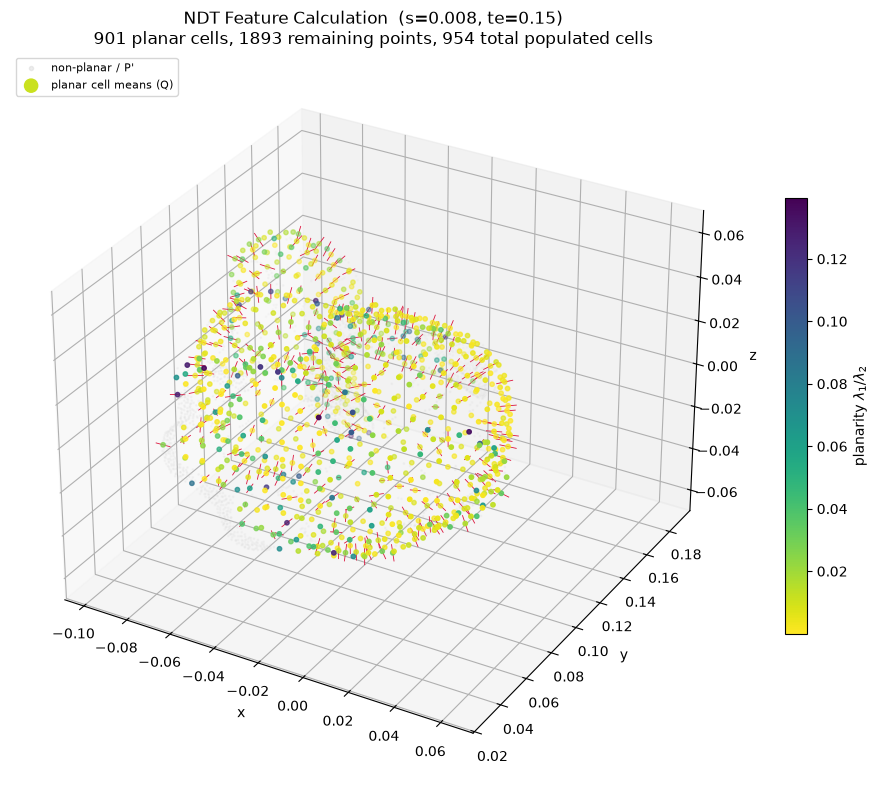

In [36]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

if len(Pp):
    step = max(1, len(Pp) // 8000)
    ax.scatter(Pp[::step, 0], Pp[::step, 1], Pp[::step, 2],
               s=1, c="lightgray", alpha=0.4, label="non-planar / P'")

if Q:
    centers = np.array([c.mean for c in Q])
    planarity = np.array([c.planarity for c in Q])
    sc = ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2],
                     s=10, c=planarity, cmap="viridis_r", label="planar cell means (Q)")
    fig.colorbar(sc, ax=ax, shrink=0.6, label=r"planarity $\lambda_1/\lambda_2$")

    step_n = max(1, len(Q) // 300)
    L = CELL_SIZE * 0.8
    for c in Q[::step_n]:
        n = c.normal
        p0, p1 = c.mean - L * n / 2, c.mean + L * n / 2
        ax.plot([p0[0], p1[0]], [p0[1], p1[1]], [p0[2], p1[2]], c="crimson", linewidth=0.6)

ax.set_title(f"NDT Feature Calculation  (s={CELL_SIZE}, te={TE})\n"
             f"{len(Q)} planar cells, {len(Pp)} remaining points, {len(A)} total populated cells")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.legend(loc="upper left", markerscale=3, fontsize=8)
fig.tight_layout()
plt.show()

## Diagnostic: distribution of planarity ratios

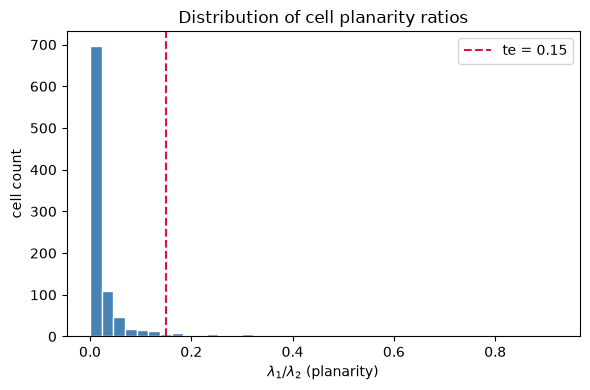

In [37]:
ratios = np.array([c.eigvals[0] / c.eigvals[1] for c in A])

fig2, ax2 = plt.subplots(figsize=(6, 4))
ax2.hist(ratios, bins=40, color="steelblue", edgecolor="white")
ax2.axvline(TE, color="crimson", linestyle="--", label=f"te = {TE}")
ax2.set_xlabel(r"$\lambda_1 / \lambda_2$ (planarity)")
ax2.set_ylabel("cell count")
ax2.set_title("Distribution of cell planarity ratios")
ax2.legend()
fig2.tight_layout()
plt.show()

## Optional: save outputs to disk

In [38]:
import os
OUT_DIR = "./ndt_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

np.savez(os.path.join(OUT_DIR, "ndt_cells.npz"),
         means=np.array([c.mean for c in Q]),
         covariances=np.array([c.cov for c in Q]),
         eigvals=np.array([c.eigvals for c in Q]),
         eigvecs=np.array([c.eigvecs for c in Q]),
         planarity=np.array([c.planarity for c in Q]))

def save_point_cloud_ply(path, pts):
    header = ("ply\nformat ascii 1.0\n"
              f"element vertex {len(pts)}\n"
              "property float x\nproperty float y\nproperty float z\n"
              "end_header\n")
    with open(path, "w") as f:
        f.write(header)
        np.savetxt(f, pts, fmt="%.6f")

save_point_cloud_ply(os.path.join(OUT_DIR, "remaining_points.ply"), Pp)
print(f"Saved to {os.path.abspath(OUT_DIR)}")

Saved to /workspaces/LocalEstimator/ndt_outputs


## Plot covariance ellipsoids for planar cells

Each planar cell's Σ defines a 3D Gaussian; drawing the `n_std`-scaled
ellipsoid (using the cell's eigenvalues/eigenvectors) shows the actual
flattened "wafer" shape NDT is detecting — you'll see thin disks lying
flat against the surface, oriented by `e2`/`e3` with `e1` (the normal)
nearly collapsed.

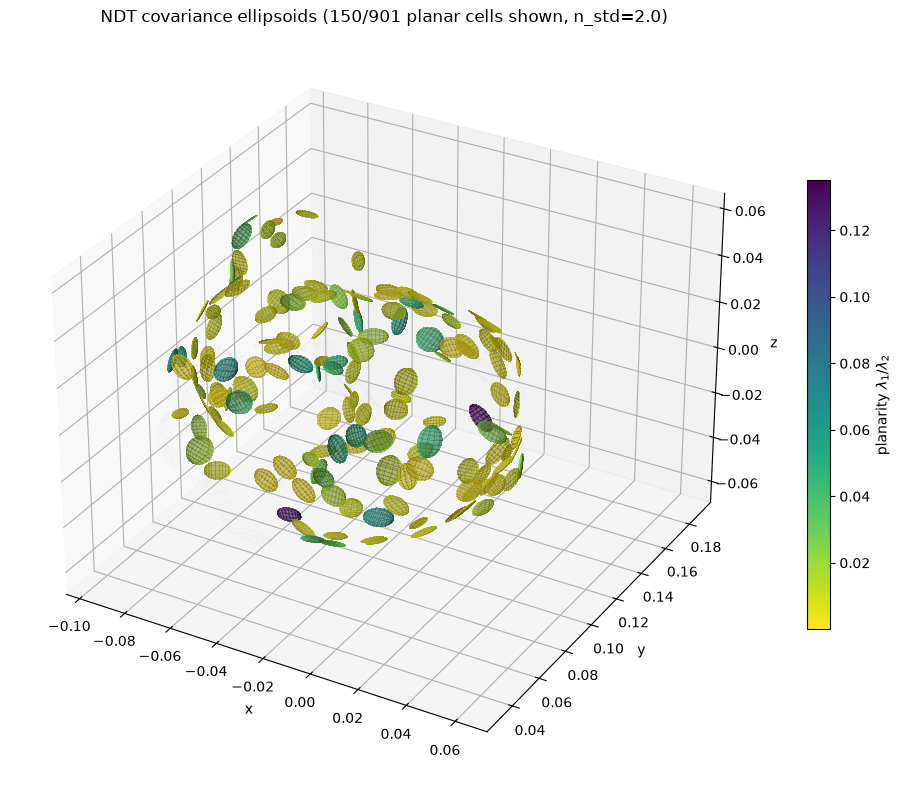

In [39]:
def ellipsoid_surface(mean, eigvals, eigvecs, n_std=2.0, resolution=12):
    """Parametric surface points (x, y, z) of the covariance ellipsoid
    for one NDT cell, scaled to n_std standard deviations."""
    u = np.linspace(0, 2 * np.pi, resolution)
    v = np.linspace(0, np.pi, resolution)
    xs = np.outer(np.cos(u), np.sin(v))
    ys = np.outer(np.sin(u), np.sin(v))
    zs = np.outer(np.ones_like(u), np.cos(v))

    # scale unit sphere by n_std * sqrt(eigenvalue) along each principal axis
    radii = n_std * np.sqrt(eigvals)
    pts = np.stack([xs, ys, zs], axis=-1) * radii            # (res, res, 3)
    pts = pts @ eigvecs.T                                     # rotate into world frame
    pts = pts + mean                                          # translate to cell mean
    return pts[..., 0], pts[..., 1], pts[..., 2]


def plot_ndt_ellipsoids(Q, Pp=None, n_std=2.0, max_cells=150,
                          color_by="planarity", cmap="viridis_r",
                          alpha=0.35, figsize=(10, 8)):
    """Plot covariance ellipsoids for (a subsample of) planar cells Q,
    optionally with the remaining points Pp shown as a light backdrop."""
    if len(Q) == 0:
        print("No planar cells in Q to plot -- lower `te`, lower `CELL_SIZE`, "
              "or check `min_points` (see planarity histogram above).")
        return None, None

    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111, projection="3d")

    if Pp is not None and len(Pp):
        step = max(1, len(Pp) // 6000)
        ax.scatter(Pp[::step, 0], Pp[::step, 1], Pp[::step, 2],
                   s=1, c="lightgray", alpha=0.25, label="P' (non-planar)")

    cells_to_plot = Q if len(Q) <= max_cells else \
        [Q[i] for i in np.linspace(0, len(Q) - 1, max_cells).astype(int)]

    if color_by == "planarity":
        values = np.array([c.planarity for c in cells_to_plot])
    else:
        values = np.zeros(len(cells_to_plot))
    norm = plt.Normalize(values.min(), values.max() + 1e-12)
    colormap = plt.get_cmap(cmap)

    for c, val in zip(cells_to_plot, values):
        x, y, z = ellipsoid_surface(c.mean, c.eigvals, c.eigvecs, n_std=n_std)
        ax.plot_surface(x, y, z, color=colormap(norm(val)), alpha=alpha,
                         linewidth=0, shade=True, antialiased=False)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    fig.colorbar(sm, ax=ax, shrink=0.6, label=r"planarity $\lambda_1/\lambda_2$")

    ax.set_title(f"NDT covariance ellipsoids ({len(cells_to_plot)}/{len(Q)} planar cells shown, "
                 f"n_std={n_std})")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    fig.tight_layout()
    return fig, ax


fig, ax = plot_ndt_ellipsoids(Q, Pp, n_std=2.0, max_cells=150)
plt.show()

## Algorithm 2 + 3: NDT-RANSAC Plane Segmentation & IRLS Plane Fitting

`Q` (planar NDT cells) and `Pp` (P') from Algorithm 1 feed straight into these.

**Note on the pseudocode:** two lines are ambiguous/garbled in the source text
(common with OCR'd paper pseudocode), so a couple of implementation choices
were made explicit rather than literal:

- Algorithm 2's `θ_i = n_i · n` is written as a dot product, but the accept
  condition `θ_i < Δθ` only makes sense as an **angle** (aligned normals
  should pass, and a dot product is *largest*, not smallest, when aligned).
  Implemented as `θ_i = arccos(|n_i · n|)` in degrees — `abs()` because a
  cell's normal direction (+e1 vs -e1) is arbitrary.
- Algorithm 3's weighted mean/covariance update line is garbled in the
  source. Implemented as the standard IRLS pattern: reweight every point by
  a **Welsch weight** computed from its current residual, recompute the
  weighted mean and weighted covariance, then re-extract the normal as the
  eigenvector of the smallest eigenvalue of the reweighted covariance.

In [40]:
# ---------------------------------------------------------------- #
# Algorithm 3: IRLS Plane Fitting
# ---------------------------------------------------------------- #
def welsch_weight(r, c):
    """Welsch M-estimator weight function. r: residuals, c: scale constant."""
    return np.exp(-(r / c) ** 2)


def irls_plane_fit(points, k_iter=50, gamma=1e-4, welsch_c=None):
    """
    Algorithm 3: robust plane normal refinement via Iteratively Reweighted
    Least Squares with a Welsch weight function.

    welsch_c: fixed scale constant, or None to recompute each iteration
              from the residuals via 1.4826 * MAD(r) (robust scale estimate).

    Returns dict: normal, mean, eigvals, eigvecs, iterations, converged, history
    """
    P = np.asarray(points, dtype=np.float64)
    if len(P) < 3:
        raise ValueError("Need at least 3 points to fit a plane.")

    X_bar = P.mean(axis=0)
    centered = P - X_bar
    C = (centered.T @ centered) / max(len(P) - 1, 1)
    eigvals, eigvecs = np.linalg.eigh(C)     # ascending
    n = eigvecs[:, 0]                        # e1 = normal

    mean_cur = X_bar.copy()
    history = []
    converged = False
    k = 0

    for k in range(1, k_iter + 1):
        n_old = n.copy()

        r = (P - mean_cur) @ n
        c = welsch_c if welsch_c is not None else \
            1.4826 * np.median(np.abs(r - np.median(r))) + 1e-12
        w = welsch_weight(r, c)
        w_sum = w.sum()

        mean_cur = (w[:, None] * P).sum(axis=0) / w_sum
        centered_w = P - mean_cur
        C = (w[:, None] * centered_w).T @ centered_w / w_sum

        eigvals, eigvecs = np.linalg.eigh(C)
        n = eigvecs[:, 0]
        if np.dot(n, n_old) < 0:
            n = -n

        convg = np.max(np.abs(n_old - n) / (np.abs(n_old) + 1e-12))
        history.append({"iter": k, "convg": convg, "welsch_c": c})

        if convg < gamma:
            converged = True
            break

    return {"normal": n, "mean": mean_cur, "eigvals": eigvals, "eigvecs": eigvecs,
            "iterations": k, "converged": converged, "history": history}

In [41]:
# ---------------------------------------------------------------- #
# Algorithm 2: NDT-RANSAC Plane Segmentation
# ---------------------------------------------------------------- #
def ndt_ransac_plane_segmentation(Q, Pp, k_max=500, eta=0.99,
                                    delta_d=0.02, delta_theta_deg=10.0,
                                    irls_kwargs=None, rng=None):
    """
    Algorithm 2: extract a single dominant plane from planar NDT cells Q,
    refine it with Algorithm 3 (IRLS), then grow it into leftover points P'.

    Returns dict: g, n (refined plane point + unit normal), inlier_cells,
    inlier_points, matched_mask_Pp, k_used, irls_result
    """
    if rng is None:
        rng = np.random.default_rng()
    if irls_kwargs is None:
        irls_kwargs = {}

    N = len(Q)
    if N == 0:
        raise ValueError("Q is empty -- no planar cells to sample from.")

    cell_means = np.array([c.mean for c in Q])
    cell_normals = np.array([c.normal for c in Q])

    I_max = 0
    best = None
    k = 0
    k_max_current = k_max

    while k < k_max_current:
        c = Q[rng.integers(0, N)]
        g, n = c.mean, c.normal

        d = np.abs((cell_means - g) @ n)
        cos_theta = np.clip(np.abs(cell_normals @ n), -1.0, 1.0)
        theta_deg = np.degrees(np.arccos(cos_theta))

        mask = (d < delta_d) & (theta_deg < delta_theta_deg)
        I_k = [Q[i] for i in np.where(mask)[0]]

        if len(I_k) > I_max:
            I_max = len(I_k)
            best = {"g": g, "n": n, "I": I_k}

            Pn = I_max / N
            if 0 < Pn < 1:
                # Equation (3): adaptive RANSAC iteration count, s=1 sample/cell
                new_k_max = int(np.ceil(np.log(1 - eta) / np.log(1 - Pn)))
                k_max_current = min(k_max_current, max(new_k_max, k + 1))

        k += 1

    if best is None:
        raise RuntimeError("RANSAC found no supporting cells; "
                            "loosen delta_d / delta_theta_deg.")

    # refine plane Psi via Algorithm 3 on the inlier cells' points
    inlier_cell_points = np.concatenate([c.points for c in best["I"]], axis=0)
    irls_result = irls_plane_fit(inlier_cell_points, **irls_kwargs)
    g_refined, n_refined = irls_result["mean"], irls_result["normal"]

    # grow the plane into P'
    if len(Pp):
        d_j = np.abs((Pp - g_refined) @ n_refined)
        matched_mask_Pp = d_j < delta_d
    else:
        matched_mask_Pp = np.zeros(0, dtype=bool)

    inlier_points = np.concatenate(
        [inlier_cell_points, Pp[matched_mask_Pp]] if matched_mask_Pp.any()
        else [inlier_cell_points], axis=0)

    return {"g": g_refined, "n": n_refined, "inlier_cells": best["I"],
            "inlier_points": inlier_points, "matched_mask_Pp": matched_mask_Pp,
            "k_used": k, "irls_result": irls_result}


def extract_multiple_planes(Q, Pp, max_planes=6, min_cells=15, **ransac_kwargs):
    """
    Convenience wrapper (not in the original pseudocode): repeatedly run
    Algorithm 2, remove the consumed cells/points, and repeat -- the usual
    way NDT-RANSAC segments ALL dominant planes rather than just the
    single strongest one. Stops at `max_planes` or when fewer than
    `min_cells` planar cells remain.
    """
    Q_remaining = list(Q)
    Pp_remaining = np.asarray(Pp, dtype=np.float64)
    planes = []

    for _ in range(max_planes):
        if len(Q_remaining) < min_cells:
            break
        result = ndt_ransac_plane_segmentation(Q_remaining, Pp_remaining, **ransac_kwargs)
        planes.append(result)

        inlier_ids = {id(c) for c in result["inlier_cells"]}
        Q_remaining = [c for c in Q_remaining if id(c) not in inlier_ids]
        if len(Pp_remaining):
            Pp_remaining = Pp_remaining[~result["matched_mask_Pp"]]

    return planes, Q_remaining, Pp_remaining

### Run it

`delta_d` and `delta_theta_deg` are the two thresholds you'll actually tune —
`delta_d` should be a few times your point-cloud noise level (start around
`2-3 x CELL_SIZE`), `delta_theta_deg` typically 5-15°.

In [42]:
K_MAX = 500
ETA = 0.99
DELTA_D = 0.006          # distance threshold, scale to your data
DELTA_THETA_DEG = 10.0   # angle threshold in degrees

rng = np.random.default_rng(0)

# single dominant plane (Algorithm 2, calling Algorithm 3 internally)
plane = ndt_ransac_plane_segmentation(Q, Pp, k_max=K_MAX, eta=ETA,
                                        delta_d=DELTA_D, delta_theta_deg=DELTA_THETA_DEG,
                                        rng=rng)
print(f"Dominant plane: {len(plane['inlier_cells'])} support cells, "
      f"{len(plane['inlier_points'])} total points")
print(f"normal n = {plane['n']}, point on plane g = {plane['g']}")
print(f"IRLS: {plane['irls_result']['iterations']} iterations, "
      f"converged={plane['irls_result']['converged']}")

# all dominant planes (bonus helper, loops Algorithm 2)
planes, Q_leftover, Pp_leftover = extract_multiple_planes(
    Q, Pp, max_planes=6, min_cells=15, k_max=K_MAX, eta=ETA,
    delta_d=DELTA_D, delta_theta_deg=DELTA_THETA_DEG, rng=rng)

for i, p in enumerate(planes):
    print(f"  plane {i}: {len(p['inlier_cells'])} cells, "
          f"{len(p['inlier_points'])} points, n={np.round(p['n'], 3)}")
print(f"cells left unassigned: {len(Q_leftover)}, points left unassigned: {len(Pp_leftover)}")

Dominant plane: 46 support cells, 1488 total points
normal n = [-0.11080308  0.9937563   0.01308039], point on plane g = [-0.0287939   0.03677894  0.01390356]
IRLS: 31 iterations, converged=True
  plane 0: 46 cells, 1473 points, n=[-0.113  0.994  0.011]
  plane 1: 19 cells, 425 points, n=[-0.073  0.357  0.931]
  plane 2: 18 cells, 369 points, n=[ 0.233 -0.182 -0.955]
  plane 3: 17 cells, 322 points, n=[ 0.039 -0.625  0.779]
  plane 4: 15 cells, 401 points, n=[ 0.065 -0.404  0.913]
  plane 5: 11 cells, 294 points, n=[ 0.837 -0.072  0.543]
cells left unassigned: 775, points left unassigned: 1077


### Visualize the extracted planes

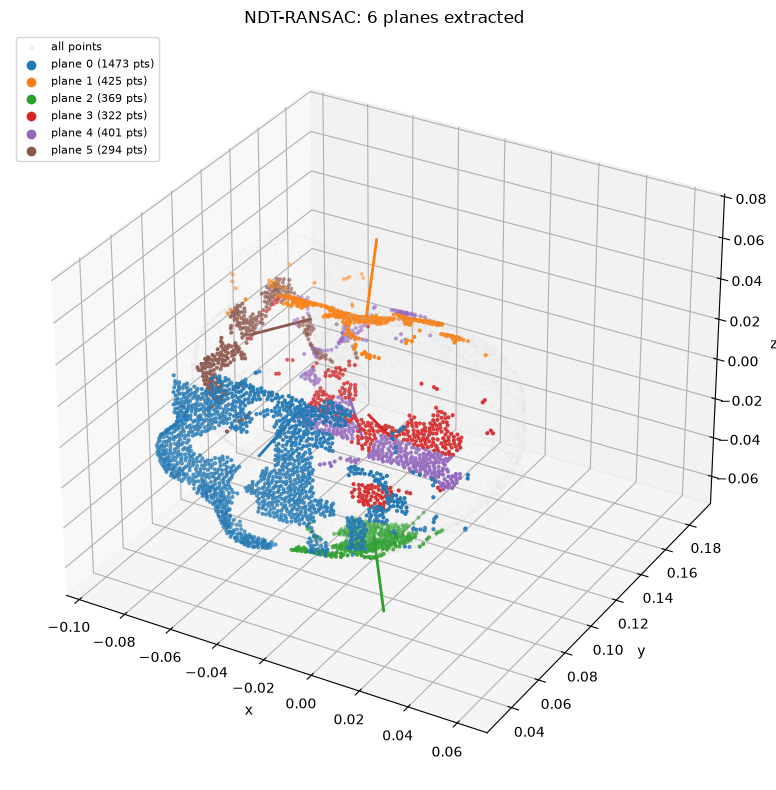

In [43]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

step = max(1, len(points) // 8000)
ax.scatter(points[::step, 0], points[::step, 1], points[::step, 2],
           s=1, c="lightgray", alpha=0.25, label="all points")

colors = plt.get_cmap("tab10").colors
for i, p in enumerate(planes):
    ip = p["inlier_points"]
    ax.scatter(ip[:, 0], ip[:, 1], ip[:, 2], s=4, color=colors[i % len(colors)],
               label=f"plane {i} ({len(ip)} pts)")
    # draw the plane normal at its centroid
    L = CELL_SIZE * 4
    g, n = p["g"], p["n"]
    ax.plot([g[0], g[0] + L * n[0]], [g[1], g[1] + L * n[1]], [g[2], g[2] + L * n[2]],
            color=colors[i % len(colors)], linewidth=2)

ax.set_title(f"NDT-RANSAC: {len(planes)} planes extracted")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.legend(loc="upper left", fontsize=8, markerscale=3)
fig.tight_layout()
plt.show()